# Example scripts

In [1]:
# example dataset
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

np.random.seed(42)

n = 1000

df = pd.DataFrame({
    "Age": np.random.normal(45, 15, n).clip(18, 90),
    "BloodPressure": np.random.normal(120, 15, n),
    "Glucose": np.random.normal(100, 25, n),
    "Cholesterol": np.random.normal(190, 30, n),

    "Gender": np.random.randint(0, 2, n),
    "Smoker": np.random.randint(0, 2, n),
    "DiabetesHistory": np.random.randint(0, 2, n),

    "Exercise": np.random.choice(
        ["Low", "Medium", "High"], n
    ),

    "BloodType": np.random.choice(
        ["A", "B", "AB", "O"], n
    )
})

# Create a risk score
risk = (
    0.025 * (df["Age"] - 45)
    + 0.035 * (df["BloodPressure"] - 120)
    + 0.025 * (df["Glucose"] - 100)
    + 0.02 * (df["Cholesterol"] - 190)
    + 0.8 * df["Smoker"]
    + 0.9 * df["DiabetesHistory"]
    + np.random.normal(0, 1, n)
)

# Binary target
df["Abnormal"] = (risk > 1.0).astype(int)

# Multiclass target
df["Diagnosis"] = pd.cut(
    risk,
    bins=[-np.inf, 0, 2, np.inf],
    labels=["Healthy", "Mild", "Severe"]
)

print(df.head())
print(df["Abnormal"].value_counts())
print(df["Diagnosis"].value_counts())


         Age  BloodPressure    Glucose  Cholesterol  Gender  Smoker  \
0  52.450712     140.990332  83.120543   132.765773       1       0   
1  42.926035     133.869505  96.387033   164.188450       0       0   
2  54.715328     120.894456  80.189502   177.591834       1       1   
3  67.845448     110.295948  92.300962   246.630630       1       0   
4  41.487699     130.473350  52.659633   206.696594       1       0   

   DiabetesHistory Exercise BloodType  Abnormal Diagnosis  
0                1   Medium         A         0      Mild  
1                0      Low        AB         0      Mild  
2                0      Low         O         0      Mild  
3                1   Medium         B         0      Mild  
4                0   Medium         A         0   Healthy  
Abnormal
0    548
1    452
Name: count, dtype: int64
Diagnosis
Mild       446
Healthy    314
Severe     240
Name: count, dtype: int64


## Question: Can you predict whether a patient is Normal or Abnormal using only binary features?

Use only:
- Gender
- Smoker
- DiabetesHistory
Target:

- Abnormal (0 = Normal, 1 = Abnormal)

Your task:
1. Split the data into training and testing sets.
2. Train Logistic Regression.
3. Train Decision Tree.
4. Train Random Forest.
5. Compare their accuracy, precision, recall and F1-score.
6. Find the best hyperparameters.

In [2]:

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, accuracy_score

X = df[["Gender", "Smoker", "DiabetesHistory"]]
y = df["Abnormal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(random_state=42)
}

for name, model in models.items():
    model.fit(X_train, y_train)
    predictions = model.predict(X_test)

    print("\n", name)
    print("Accuracy:", accuracy_score(y_test, predictions))
    print(classification_report(y_test, predictions))



 Logistic Regression
Accuracy: 0.645
              precision    recall  f1-score   support

           0       0.65      0.78      0.71       110
           1       0.64      0.48      0.55        90

    accuracy                           0.65       200
   macro avg       0.64      0.63      0.63       200
weighted avg       0.64      0.65      0.64       200


 Decision Tree
Accuracy: 0.645
              precision    recall  f1-score   support

           0       0.65      0.78      0.71       110
           1       0.64      0.48      0.55        90

    accuracy                           0.65       200
   macro avg       0.64      0.63      0.63       200
weighted avg       0.64      0.65      0.64       200


 Random Forest
Accuracy: 0.645
              precision    recall  f1-score   support

           0       0.65      0.78      0.71       110
           1       0.64      0.48      0.55        90

    accuracy                           0.65       200
   macro avg       0.64   

In [3]:
# finding best parameters:

param_grid = {
    "n_estimators": [50, 100, 200],
    "max_depth": [None, 3, 5, 10],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4]
}

grid = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV F1:", grid.best_score_)


Best parameters: {'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 2, 'n_estimators': 50}
Best CV F1: 0.5396348127844695


## Exercise 2 — Binary classification using continuous features
Binary classification
Question: Can you predict Normal vs Abnormal using only continuous measurements?

Use:
- Age
- BloodPressure
- Glucose
- Cholesterol
Target: Abnormal

This time, experiment with scaling because the features have different numerical ranges.

Try these models:

Model	Why use it?

Logistic Regression	Linear classification

KNN	Distance-based classification

SVM	Finds separating boundaries

Gaussian Naive Bayes	Uses Gaussian feature distributions

Random Forest	Learns nonlinear relationships

In [4]:

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.naive_bayes import GaussianNB

X = df[[
    "Age",
    "BloodPressure",
    "Glucose",
    "Cholesterol"
]]

y = df["Abnormal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=1000)
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier()
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        SVC()
    ),

    "Gaussian NB": GaussianNB(),

    "Random Forest": RandomForestClassifier(
        random_state=42
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print(name, accuracy_score(y_test, pred))


Logistic Regression 0.74
KNN 0.71
SVM 0.725
Gaussian NB 0.74
Random Forest 0.69


In [8]:

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.model_selection import GridSearchCV

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("svc", SVC())
])

param_grid = {
    "svc__C": [0.1, 1, 10, 100],
    "svc__kernel": ["linear", "rbf", "poly"],
    "svc__gamma": ["scale", "auto", 0.01, 0.1, 1]
}

grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV F1:", grid.best_score_)

best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)


Best parameters: {'svc__C': 10, 'svc__gamma': 0.01, 'svc__kernel': 'rbf'}
Best CV F1: 0.7160986813432997


## Exercise 3 — Multiclass classification
Multiclass classification
Question: Can you classify patients into three different diagnosis categories?

Target:
- Healthy
- Mild
- Severe
Use continuous features:
- Age
- BloodPressure
- Glucose
- Cholesterol
Try:
1. Logistic Regression
2. KNN
3. Decision Tree
4. Random Forest
5. SVM

In [9]:

X = df[[
    "Age",
    "BloodPressure",
    "Glucose",
    "Cholesterol"
]]

y = df["Diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

models = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(max_iter=2000)
    ),

    "KNN": make_pipeline(
        StandardScaler(),
        KNeighborsClassifier()
    ),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        random_state=42
    ),

    "SVM": make_pipeline(
        StandardScaler(),
        SVC()
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print("\n", name)
    print(classification_report(y_test, pred))



 Logistic Regression
              precision    recall  f1-score   support

     Healthy       0.64      0.48      0.55        63
        Mild       0.53      0.70      0.60        89
      Severe       0.66      0.48      0.55        48

    accuracy                           0.57       200
   macro avg       0.61      0.55      0.57       200
weighted avg       0.59      0.57      0.57       200


 KNN
              precision    recall  f1-score   support

     Healthy       0.51      0.56      0.53        63
        Mild       0.51      0.55      0.53        89
      Severe       0.51      0.38      0.43        48

    accuracy                           0.51       200
   macro avg       0.51      0.49      0.50       200
weighted avg       0.51      0.51      0.51       200


 Decision Tree
              precision    recall  f1-score   support

     Healthy       0.41      0.41      0.41        63
        Mild       0.42      0.38      0.40        89
      Severe       0.39      0.

## Exercise 4 — Multiclass classification with one-hot encoding
Categorical data
Question: Can you predict the diagnosis using categorical and binary variables?

Use:
- Gender
- Smoker
- DiabetesHistory
- Exercise
- BloodType
Target: Diagnosis

This is where one-hot encoding becomes important.

For example:
Exercise	Exercise_High	Exercise_Low	Exercise_Medium
High	1	0	0
Low	0	1	0
Medium	0	0	1

In [11]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder

binary_features = [
    "Gender",
    "Smoker",
    "DiabetesHistory"
]

categorical_features = [
    "Exercise",
    "BloodType"
]

preprocessor = ColumnTransformer([
    ("binary", "passthrough", binary_features),

    ("categorical",
     OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])

X = df[binary_features + categorical_features]
y = df["Diagnosis"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(max_iter=2000))
])

model.fit(X_train, y_train)

pred = model.predict(X_test)
print(classification_report(y_test, pred))


['Mild' 'Healthy' 'Mild' 'Mild' 'Mild' 'Healthy' 'Mild' 'Healthy' 'Mild'
 'Mild' 'Mild' 'Mild' 'Mild' 'Mild' 'Healthy' 'Healthy' 'Mild' 'Mild'
 'Mild' 'Mild' 'Mild' 'Mild' 'Healthy' 'Mild' 'Mild' 'Mild' 'Mild'
 'Healthy' 'Healthy' 'Mild' 'Mild' 'Mild' 'Mild' 'Mild' 'Mild' 'Healthy'
 'Mild' 'Mild' 'Mild' 'Mild' 'Healthy' 'Mild' 'Severe' 'Mild' 'Mild'
 'Mild' 'Healthy' 'Mild' 'Mild' 'Mild' 'Healthy' 'Mild' 'Mild' 'Mild'
 'Mild' 'Mild' 'Mild' 'Mild' 'Mild' 'Mild' 'Healthy' 'Mild' 'Mild' 'Mild'
 'Mild' 'Mild' 'Mild' 'Healthy' 'Healthy' 'Mild' 'Mild' 'Mild' 'Mild'
 'Mild' 'Mild' 'Mild' 'Mild' 'Mild' 'Mild' 'Mild' 'Mild' 'Mild' 'Healthy'
 'Healthy' 'Healthy' 'Mild' 'Healthy' 'Healthy' 'Mild' 'Healthy' 'Mild'
 'Mild' 'Healthy' 'Mild' 'Healthy' 'Mild' 'Mild' 'Mild' 'Mild' 'Healthy'
 'Healthy' 'Mild' 'Severe' 'Mild' 'Mild' 'Healthy' 'Mild' 'Healthy' 'Mild'
 'Mild' 'Mild' 'Healthy' 'Mild' 'Mild' 'Mild' 'Severe' 'Mild' 'Mild'
 'Mild' 'Severe' 'Mild' 'Mild' 'Mild' 'Mild' 'Healthy' 'Mild' 'Healthy'

In [12]:
param_grid = [
    {
        "classifier": [
            LogisticRegression(max_iter=2000)
        ],
        "classifier__C": [0.01, 0.1, 1, 10, 100]
    },
    {
        "classifier": [
            RandomForestClassifier(random_state=42)
        ],
        "classifier__n_estimators": [50, 100, 200],
        "classifier__max_depth": [None, 5, 10]
    },
    {
        "classifier": [
            DecisionTreeClassifier(random_state=42)
        ],
        "classifier__max_depth": [2, 3, 5, 10],
        "classifier__min_samples_split": [2, 5, 10]
    }
]

grid = GridSearchCV(
    model,
    param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print(grid.best_params_)
print(grid.best_score_)

{'classifier': RandomForestClassifier(random_state=42), 'classifier__max_depth': None, 'classifier__n_estimators': 50}
0.42297191367866904


4. Understanding which model to use
Here is a cheat sheet you can use when solving the exercises.
Problem	Models to experiment with

Binary features only	Logistic Regression, Decision Tree, Random Forest

Continuous features only	Logistic Regression, KNN, SVM, GaussianNB

Binary classification	Logistic Regression, SVM, Random Forest

Multiclass classification	Logistic Regression, SVM, KNN, Random Forest

Categorical features	Logistic Regression, Decision Tree, Random Forest

Mixed features	Logistic Regression, SVM, Random Forest

Gaussian distributions	GaussianNB, QDA, LDA

6. Important sklearn techniques to practice

Technique	sklearn tool

Split dataset	train_test_split

Binary encoding	Keep 0 and 1

One-hot encoding	OneHotEncoder

Numerical scaling	StandardScaler

Normalization	MinMaxScaler

Feature preprocessing	ColumnTransformer

Combine preprocessing and model	Pipeline

Hyperparameter optimization	GridSearchCV

Random hyperparameter optimization	RandomizedSearchCV

Cross-validation	StratifiedKFold

Classification evaluation	classification_report

Confusion matrix	confusion_matrix

ROC curve	roc_curve

AUC	roc_auc_score

## 1. Understand the models first
Model	Main assumption	Suitable data
* LDA	Classes have Gaussian distributions with equal covariance matrices	Continuous
* QDA	Classes have Gaussian distributions with different covariance matrices	Continuous
* GaussianNB	Features follow Gaussian distributions within each class	Continuous
* BernoulliNB	Features are binary (0 or 1)	Binary
* MultinomialNB	Features represent non-negative counts or frequencies	Count data
* ComplementNB	Designed for count data, often useful for imbalanced text classification	Count data



# LDA


In [14]:

from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report
from sklearn.model_selection import train_test_split

X = df[
    ["Age", "BloodPressure", "Glucose", "Cholesterol"]
]

y = df["Abnormal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("lda", LinearDiscriminantAnalysis())
])


param_grid = [
    {
        "lda__solver": ["svd"]
    },
    {
        "lda__solver": ["lsqr", "eigen"],
        "lda__shrinkage": [None, "auto", 0.1, 0.5, 0.9]
    }
]


grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV F1:", grid.best_score_)

best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)

print(classification_report(y_test, y_pred))


Best parameters: {'lda__solver': 'svd'}
Best CV F1: 0.7152436776810758
              precision    recall  f1-score   support

           0       0.73      0.84      0.78       110
           1       0.76      0.62      0.68        90

    accuracy                           0.74       200
   macro avg       0.74      0.73      0.73       200
weighted avg       0.74      0.74      0.74       200



# QDA

In [15]:

from sklearn.discriminant_analysis import QuadraticDiscriminantAnalysis

pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("qda", QuadraticDiscriminantAnalysis())
])

param_grid = {
    "qda__reg_param": [0, 0.01, 0.1, 0.5, 0.9]
}

grid = GridSearchCV(
    pipeline,
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV F1:", grid.best_score_)

best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)

print(classification_report(y_test, y_pred))


Best parameters: {'qda__reg_param': 0.5}
Best CV F1: 0.7081269578918321
              precision    recall  f1-score   support

           0       0.73      0.83      0.77       110
           1       0.75      0.62      0.68        90

    accuracy                           0.73       200
   macro avg       0.74      0.72      0.73       200
weighted avg       0.74      0.73      0.73       200



# Gaussian Naive Bayes

In [16]:

from sklearn.naive_bayes import GaussianNB

model = GaussianNB()

param_grid = {
    "var_smoothing": [
        1e-12,
        1e-10,
        1e-9,
        1e-8,
        1e-6,
        1e-4
    ]
}

grid = GridSearchCV(
    model,
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV F1:", grid.best_score_)

best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)

print(classification_report(y_test, y_pred))


Best parameters: {'var_smoothing': 1e-12}
Best CV F1: 0.7036258396571086
              precision    recall  f1-score   support

           0       0.73      0.83      0.78       110
           1       0.75      0.63      0.69        90

    accuracy                           0.74       200
   macro avg       0.74      0.73      0.73       200
weighted avg       0.74      0.74      0.74       200



# Bernoulli Naive Bayes

In [17]:

from sklearn.naive_bayes import BernoulliNB

X = df[
    ["Gender", "Smoker", "DiabetesHistory"]
]

y = df["Abnormal"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

model = BernoulliNB()

param_grid = {
    "alpha": [0.001, 0.01, 0.1, 0.5, 1, 5, 10],
    "binarize": [None],
    "fit_prior": [True, False]
}

grid = GridSearchCV(
    model,
    param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV F1:", grid.best_score_)

y_pred = grid.best_estimator_.predict(X_test)

print(classification_report(y_test, y_pred))


Best parameters: {'alpha': 0.001, 'binarize': None, 'fit_prior': False}
Best CV F1: 0.5760000425904316
              precision    recall  f1-score   support

           0       0.67      0.63      0.65       110
           1       0.58      0.62      0.60        90

    accuracy                           0.62       200
   macro avg       0.62      0.62      0.62       200
weighted avg       0.63      0.62      0.63       200



# Multinomial Naive Bayes

In [18]:

# Create synthetic symptom count dataset

X_counts = pd.DataFrame({
    "Headache": np.random.poisson(2, 1000),
    "Fatigue": np.random.poisson(3, 1000),
    "Fever": np.random.poisson(1, 1000),
    "Cough": np.random.poisson(2, 1000),
    "Pain": np.random.poisson(2, 1000)
})

# Create a multiclass target
y_counts = np.random.choice(
    ["Healthy", "Mild", "Severe"],
    size=1000,
    p=[0.4, 0.35, 0.25]
)

X_train, X_test, y_train, y_test = train_test_split(
    X_counts, y_counts,
    test_size=0.2,
    random_state=42,
    stratify=y_counts
)

from sklearn.naive_bayes import MultinomialNB

param_grid = {
    "alpha": [0.001, 0.01, 0.1, 0.5, 1, 5, 10],
    "fit_prior": [True, False]
}

grid = GridSearchCV(
    MultinomialNB(),
    param_grid,
    cv=5,
    scoring="f1_macro",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best CV F1:", grid.best_score_)

y_pred = grid.best_estimator_.predict(X_test)

print(classification_report(y_test, y_pred))


Best parameters: {'alpha': 0.001, 'fit_prior': False}
Best CV F1: 0.3480498660019158
              precision    recall  f1-score   support

     Healthy       0.38      0.34      0.36        77
        Mild       0.39      0.43      0.41        68
      Severe       0.27      0.27      0.27        55

    accuracy                           0.35       200
   macro avg       0.34      0.35      0.34       200
weighted avg       0.35      0.35      0.35       200



In [20]:

from sklearn.model_selection import GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

from sklearn.discriminant_analysis import (
    LinearDiscriminantAnalysis,
    QuadraticDiscriminantAnalysis
)

from sklearn.naive_bayes import GaussianNB

models = {
    "LDA": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", LinearDiscriminantAnalysis())
        ]),
        [
            {"model__solver": ["svd"]},
            {
                "model__solver": ["lsqr", "eigen"],
                "model__shrinkage": [
                    None, "auto", 0.1, 0.5
                ]
            }
        ]
    ),

    "QDA": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", QuadraticDiscriminantAnalysis())
        ]),
        {
            "model__reg_param": [
                0, 0.01, 0.1, 0.5, 0.9
            ]
        }
    ),

    "GaussianNB": (
        Pipeline([
            ("scaler", StandardScaler()),
            ("model", GaussianNB())
        ]),
        {
            "model__var_smoothing": [
                1e-12, 1e-10, 1e-9,
                1e-8, 1e-6, 1e-4
            ]
        }
    )
}

results = {}

for name, (pipeline, params) in models.items():

    grid = GridSearchCV(
        pipeline,
        params,
        cv=5,
        scoring="f1_macro",
        n_jobs=-1
    )

    grid.fit(X_train, y_train)

    results[name] = {
        "Best parameters": grid.best_params_,
        "CV F1": grid.best_score_
    }

    print("\n", name)
    print("Best parameters:", grid.best_params_)
    print("Best F1:", grid.best_score_)



 LDA
Best parameters: {'model__shrinkage': None, 'model__solver': 'lsqr'}
Best F1: 0.2789182655425576

 QDA
Best parameters: {'model__reg_param': 0}
Best F1: 0.33113309530514645

 GaussianNB
Best parameters: {'model__var_smoothing': 1e-12}
Best F1: 0.2756565664475231


# scalar

The general rule is:
- Models based on distances, gradients or numerical optimization usually benefit from scaling.
- Models based on decision trees generally do not need scaling.
- Some statistical models have distribution assumptions that are not solved by scaling.

1. When should you use a scaler?
Here is a practical overview.
Model	Scale features?	Reason
- Logistic Regression	Yes	Helps optimization and regularization
- Linear Regression	Usually	Helps numerical optimization, especially with regularization
- KNN	Yes	Uses distances
- SVM	Yes	Sensitive to feature magnitudes
- LDA	Usually not necessary	Covariance-based model
- QDA	Usually not necessary	Covariance-based model
- Gaussian Naive Bayes	Usually not necessary	Estimates Gaussian distributions
- BernoulliNB	No	Uses binary features
- MultinomialNB	No	Uses non-negative counts
- Decision Tree	No	Uses feature thresholds
- Random Forest	No	Uses decision trees
- Gradient Boosting	Usually no	Tree-based splits
- XGBoost	Usually no	Tree-based splits

5. How to combine scaling and one-hot encoding?
This is one of the most useful things to learn in sklearn.

Suppose your dataset contains:
- Continuous: Age, Glucose, BloodPressure
- Binary: Smoker, Gender
- Categorical: Exercise, BloodType

In [21]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)

continuous_features = [
    "Age",
    "Glucose",
    "BloodPressure"
]

binary_features = [
    "Smoker",
    "Gender"
]

categorical_features = [
    "Exercise",
    "BloodType"
]

preprocessor = ColumnTransformer([
    ("continuous", StandardScaler(), continuous_features),

    ("binary", "passthrough", binary_features),

    ("categorical",
     OneHotEncoder(handle_unknown="ignore"),
     categorical_features)
])
from sklearn.pipeline import Pipeline
from sklearn.svm import SVC

pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", SVC())
])

# XGboosting

In [26]:
import numpy as np
import pandas as pd

from sklearn.ensemble import GradientBoostingClassifier

from sklearn.model_selection import (
    train_test_split,
    GridSearchCV,
    RandomizedSearchCV
)

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    f1_score,
    roc_auc_score
)

In [28]:
X = df[
    [
        "Age",
        "BloodPressure",
        "Glucose",
        "Cholesterol",
        "Gender",
        "Smoker",
        "DiabetesHistory"
    ]
]

y = df["Abnormal"]
# We use stratify=y to maintain approximately the same class proportions in the training and test sets.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [29]:
model = GradientBoostingClassifier(
    n_estimators=100,
    learning_rate=0.1,
    max_depth=3,
    random_state=42
)

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.75

Classification Report:
              precision    recall  f1-score   support

           0       0.76      0.80      0.78       110
           1       0.74      0.69      0.71        90

    accuracy                           0.75       200
   macro avg       0.75      0.74      0.75       200
weighted avg       0.75      0.75      0.75       200


Confusion Matrix:
[[88 22]
 [28 62]]


In [30]:
param_grid = {
    "n_estimators": [50, 100, 150],
    "learning_rate": [0.05, 0.1, 0.2],
    "max_depth": [2, 3, 4],
    "min_samples_split": [2, 5, 10],
    "min_samples_leaf": [1, 2, 4],
    "subsample": [0.8, 1.0]
}

grid = GridSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1,
    verbose=1
)

grid.fit(X_train, y_train)

print("Best parameters:")
print(grid.best_params_)

print("\nBest F1 score:")
print(grid.best_score_)

Fitting 5 folds for each of 486 candidates, totalling 2430 fits
Best parameters:
{'learning_rate': 0.2, 'max_depth': 2, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 50, 'subsample': 0.8}

Best F1 score:
0.7444617978139105


## randomizedsearchCV

In [31]:
from scipy.stats import randint, uniform

param_dist = {
    "n_estimators": randint(50, 300),
    "learning_rate": uniform(0.01, 0.19),
    "max_depth": randint(2, 6),
    "min_samples_split": randint(2, 12),
    "min_samples_leaf": randint(1, 6),
    "subsample": uniform(0.7, 0.3)
}

random_search = RandomizedSearchCV(
    estimator=GradientBoostingClassifier(random_state=42),
    param_distributions=param_dist,
    n_iter=40,
    cv=5,
    scoring="f1",
    random_state=42,
    n_jobs=-1,
    verbose=1
)

random_search.fit(X_train, y_train)

Fitting 5 folds for each of 40 candidates, totalling 200 fits


,estimator,GradientBoost...ndom_state=42)
,param_distributions,"{'learning_rate': <scipy.stats....x7f3679e60980>, 'max_depth': <scipy.stats....x7f367820a990>, 'min_samples_leaf': <scipy.stats....x7f3679e7a520>, 'min_samples_split': <scipy.stats....x7f3678209d10>, ...}"
,n_iter,40
,scoring,'f1'
,n_jobs,-1
,refit,True
,cv,5
,verbose,1
,pre_dispatch,'2*n_jobs'
,random_state,42
,error_score,nan


In [32]:
print(random_search.best_params_)
print(random_search.best_score_)

{'learning_rate': np.float64(0.07042066024465414), 'max_depth': 2, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 76, 'subsample': np.float64(0.8281323365878769)}
0.7365944493517004


In [33]:
best_model = random_search.best_estimator_

y_pred = best_model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print("F1:", f1_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.72
F1: 0.6626506024096386

Classification Report:
              precision    recall  f1-score   support

           0       0.72      0.81      0.76       110
           1       0.72      0.61      0.66        90

    accuracy                           0.72       200
   macro avg       0.72      0.71      0.71       200
weighted avg       0.72      0.72      0.72       200


Confusion Matrix:
[[89 21]
 [35 55]]


In [34]:
y_prob = best_model.predict_proba(X_test)[:, 1]

print("ROC AUC:", roc_auc_score(y_test, y_prob))

ROC AUC: 0.8076767676767677


In [35]:
# feature importance:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": best_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

           Feature  Importance
2          Glucose    0.285325
3      Cholesterol    0.263570
1    BloodPressure    0.209772
0              Age    0.108300
6  DiabetesHistory    0.091782
5           Smoker    0.041252
4           Gender    0.000000


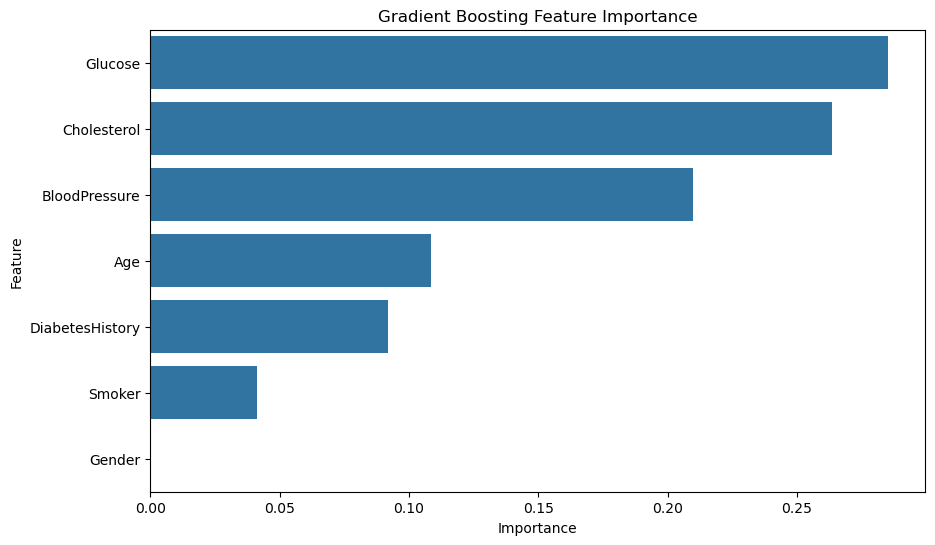

In [36]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Gradient Boosting Feature Importance")
plt.show()

# HistGradientBoostingClassifier

In [38]:
from sklearn.ensemble import HistGradientBoostingClassifier

model = HistGradientBoostingClassifier(
    learning_rate=0.1,
    max_iter=100,
    max_leaf_nodes=31,
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.73      0.82      0.77       110
           1       0.74      0.63      0.68        90

    accuracy                           0.73       200
   macro avg       0.74      0.73      0.73       200
weighted avg       0.74      0.73      0.73       200



# ID3


In [41]:
import pandas as pd
import numpy as np

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

In [44]:
X = df[
    [
        "Age",
        "BloodPressure",
        "Glucose",
        "Cholesterol",
        "Gender",
        "Smoker",
        "DiabetesHistory"
    ]
]

y = df["Abnormal"]
X = df[
    [
        "Age",
        "BloodPressure",
        "Glucose",
        "Cholesterol",
        "Gender",
        "Smoker",
        "DiabetesHistory"
    ]
]

y = df["Abnormal"]
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [45]:
model = DecisionTreeClassifier(
    criterion="entropy",
    random_state=42
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

In [46]:
print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(y_test, y_pred))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

Accuracy: 0.67

Classification Report:
              precision    recall  f1-score   support

           0       0.71      0.68      0.69       110
           1       0.63      0.66      0.64        90

    accuracy                           0.67       200
   macro avg       0.67      0.67      0.67       200
weighted avg       0.67      0.67      0.67       200


Confusion Matrix:
[[75 35]
 [31 59]]


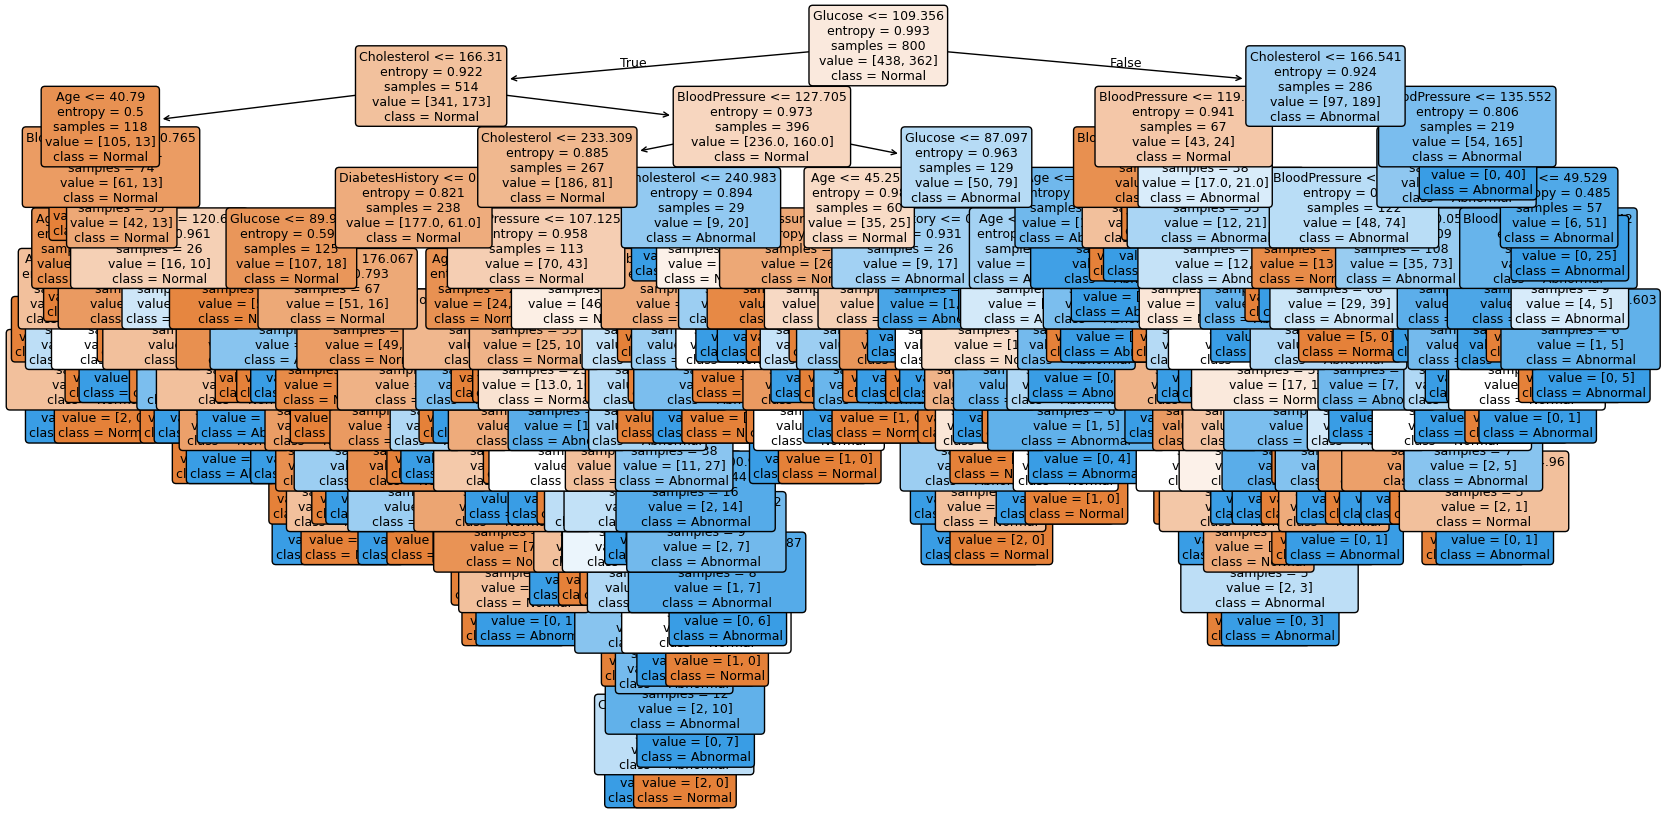

In [47]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

plt.figure(figsize=(20, 10))

plot_tree(
    model,
    feature_names=X.columns,
    class_names=["Normal", "Abnormal"],
    filled=True,
    rounded=True,
    fontsize=9
)

plt.show()

In [48]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

           Feature  Importance
2          Glucose    0.247722
3      Cholesterol    0.234873
1    BloodPressure    0.219425
0              Age    0.210698
6  DiabetesHistory    0.041963
5           Smoker    0.029879
4           Gender    0.015440


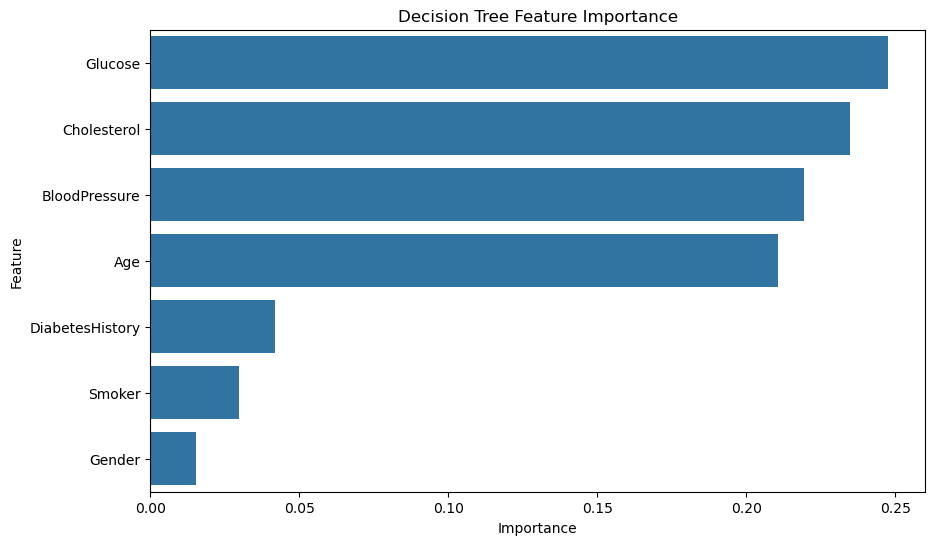

In [49]:
import seaborn as sns

plt.figure(figsize=(10, 6))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Decision Tree Feature Importance")
plt.show()

In [51]:
param_grid = {
    "criterion": ["gini", "entropy", "log_loss"],
    "max_depth": [2, 3, 4, 5, 10, None],
    "min_samples_split": [2, 5, 10, 20],
    "min_samples_leaf": [1, 2, 5, 10],
    "max_features": [None, "sqrt", "log2"]
}
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring="f1",
    n_jobs=-1
)

grid.fit(X_train, y_train)

print("Best parameters:", grid.best_params_)
print("Best F1:", grid.best_score_)

Best parameters: {'criterion': 'entropy', 'max_depth': 10, 'max_features': None, 'min_samples_leaf': 10, 'min_samples_split': 2}
Best F1: 0.676963344773341


In [52]:
best_model = grid.best_estimator_

y_pred = best_model.predict(X_test)

print(classification_report(y_test, y_pred))

              precision    recall  f1-score   support

           0       0.69      0.75      0.72       110
           1       0.66      0.58      0.62        90

    accuracy                           0.68       200
   macro avg       0.67      0.67      0.67       200
weighted avg       0.67      0.68      0.67       200



* Precision – How many of your positive predictions were correct
* Recall – How many actual positive cases did your model find?
* F1-score – A balance between precision and recall
* accuracy - Percentage of all predictions that were correct

# cheatsheet decisions


# Machine Learning Cheatsheet

## Classification
- Logistic Regression: linear classification baseline.
- KNN: similar observations; scale features.
- SVM: complex decision boundaries; scale features.
- Decision Tree: interpretable decision rules.
- Random Forest: robust ensemble of trees.
- Gradient Boosting: sequentially improves tree predictions.
- HistGradientBoosting: efficient boosting for larger datasets.
- XGBoost: powerful gradient boosting for tabular data.
- Naive Bayes: fast probabilistic baseline, especially for text.

## Regression
- Linear Regression: linear relationships.
- Ridge: correlated features; L2 regularization.
- Lasso: feature selection; L1 regularization.
- Elastic Net: combines L1 and L2.
- Random Forest Regressor: nonlinear relationships.
- Gradient Boosting Regressor: strong tabular predictions.
- SVR: nonlinear regression; scale features.

## Scaling
- StandardScaler: Logistic Regression, SVM, KNN.
- MinMaxScaler: fixed feature range.
- RobustScaler: outliers.
- Usually no scaling: Decision Trees, Random Forest,
  Gradient Boosting, XGBoost.

## Regularization
- L1: can remove features (zero coefficients).
- L2: shrinks coefficients.
- Elastic Net: combines L1 and L2.
- Ridge alpha: larger = stronger regularization.
- Lasso alpha: larger = stronger regularization.
- Logistic Regression C: smaller = stronger regularization.
- SVM C: smaller = stronger regularization.
- Trees: control max_depth, min_samples_leaf,
  min_samples_split and ccp_alpha.

## Evaluation
Classification:
- Accuracy: overall correct predictions.
- Precision: how many predicted positives were correct.
- Recall: how many actual positives were found.
- F1: balance between precision and recall.
- ROC AUC: ability to rank positives above negatives.

Regression:
- MAE: average absolute error.
- RMSE: penalizes large errors more heavily.
- R²: variance explained by the model.

## General workflow
1. Split into training and test sets.
2. Preprocess using a Pipeline.
3. Train a baseline model.
4. Compare models using cross-validation.
5. Tune hyperparameters.
6. Check for overfitting.
7. Evaluate once on the held-out test set.
